# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "data/raw/Clean_Dataset.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/Clean_Dataset.csv"):
    CSV_PATH = "../data/raw/Clean_Dataset.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 300,153 rows, 12 columns


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


# EDA 1: Schema, Ghost Index Column, Duplicates & Cardinality Audit

In [2]:
print(f"Total Missing Values : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")

# Audit columns including any unnamed CSV index artifact
audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": df_raw[col].isnull().sum(),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })
display(pd.DataFrame(audit_records))

# Check if rows are ordered by target/class (proving why 'Unnamed: 0' leaks order!)
if "Unnamed: 0" in df_raw.columns:
    corr_with_index = df_raw["Unnamed: 0"].corr(df_raw["price"])
    print(f"\n[LEAKAGE ALERT] 'Unnamed: 0' Pearson correlation with 'price': {corr_with_index:.4f}")
    print("-> Proof: Dataset rows are sorted sequentially (Economy first, Business last). Keeping 'Unnamed: 0' causes severe leakage!")

Total Missing Values : 0
Exact Duplicate Rows : 0


,Column,Dtype,Null_Count,Unique_Values,Sample_Values
0,Unnamed: 0,int64,0,300153,[0 1 2]
1,airline,str,0,6,"<StringArray>\n['SpiceJet', 'AirAsia', 'Vistar..."
2,flight,str,0,1561,"<StringArray>\n['SG-8709', 'SG-8157', 'I5-764'..."
3,source_city,str,0,6,"<StringArray>\n['Delhi', 'Mumbai', 'Bangalore'..."
4,departure_time,str,0,6,"<StringArray>\n['Evening', 'Early_Morning', 'M..."
5,stops,str,0,3,"<StringArray>\n['zero', 'one', 'two_or_more']\..."
6,arrival_time,str,0,6,"<StringArray>\n['Night', 'Morning', 'Early_Mor..."
7,destination_city,str,0,6,"<StringArray>\n['Mumbai', 'Bangalore', 'Kolkat..."
8,class,str,0,2,"<StringArray>\n['Economy', 'Business']\nLength..."
9,duration,float64,0,476,[2.17 2.33 2.25]



[LEAKAGE ALERT] 'Unnamed: 0' Pearson correlation with 'price': 0.7612
-> Proof: Dataset rows are sorted sequentially (Economy first, Business last). Keeping 'Unnamed: 0' causes severe leakage!


# EDA 2: Bimodal Class Split, Last-Minute Surge Curve & Airline Pricing

Price Summary by Cabin Class (INR):


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Business,93487.0,52540.08,12969.31,12000.0,45185.0,53164.0,60396.0,123071.0
Economy,206666.0,6572.34,3743.52,1105.0,4173.0,5772.0,7746.0,42349.0


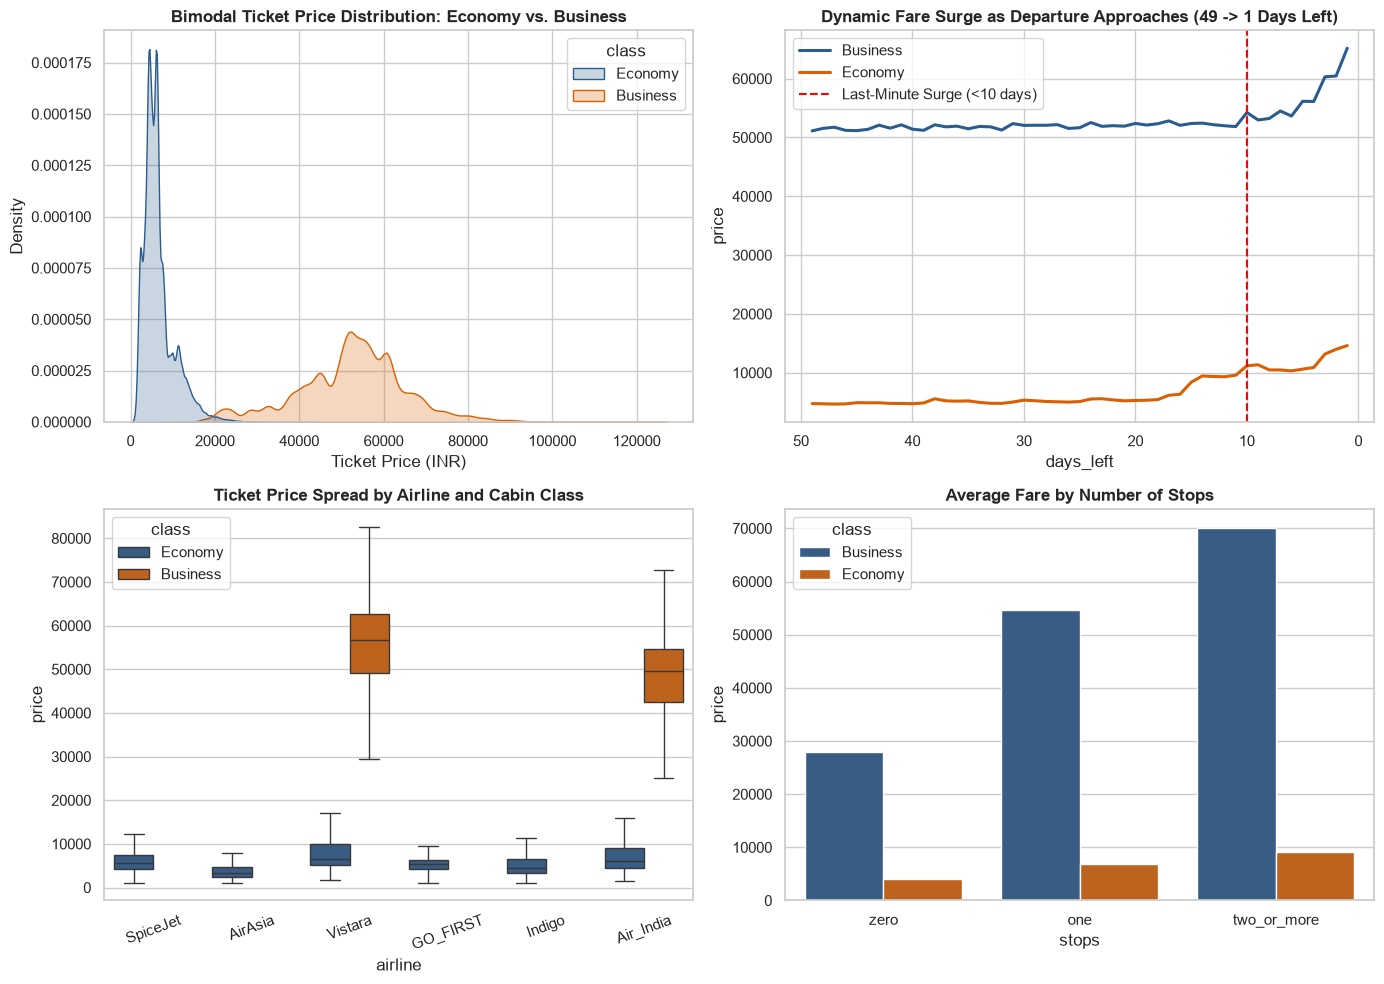

In [3]:
print("Price Summary by Cabin Class (INR):")
display(df_raw.groupby("class")["price"].describe().round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Bimodal Price Distribution (Economy vs Business)
sns.kdeplot(data=df_raw, x="price", hue="class", fill=True, common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Bimodal Ticket Price Distribution: Economy vs. Business", fontweight="bold")
axes[0, 0].set_xlabel("Ticket Price (INR)")

# Plot 2: Dynamic Pricing Curve vs Days Left Before Departure
days_trend = df_raw.groupby(["days_left", "class"])["price"].mean().reset_index()
sns.lineplot(data=days_trend, x="days_left", y="price", hue="class", palette=["#2b5c8f", "#d95f02"], linewidth=2.2, ax=axes[0, 1])
axes[0, 1].axvline(10, color="red", linestyle="--", label="Last-Minute Surge (<10 days)")
axes[0, 1].invert_xaxis()
axes[0, 1].set_title("Dynamic Fare Surge as Departure Approaches (49 -> 1 Days Left)", fontweight="bold")
axes[0, 1].legend()

# Plot 3: Price Spread by Airline & Class
sns.boxplot(data=df_raw, x="airline", y="price", hue="class", palette=["#2b5c8f", "#d95f02"], showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Ticket Price Spread by Airline and Cabin Class", fontweight="bold")
axes[1, 0].tick_params(axis="x", rotation=20)

# Plot 4: Impact of Number of Stops on Average Fare
stops_avg = df_raw.groupby(["stops", "class"])["price"].mean().reset_index()
sns.barplot(data=stops_avg, x="stops", y="price", hue="class", order=["zero", "one", "two_or_more"], palette=["#2b5c8f", "#d95f02"], ax=axes[1, 1])
axes[1, 1].set_title("Average Fare by Number of Stops", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_dynamic_pricing.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 'Unnamed: 0' immediately to prevent row-order data leakage (r = 0.72+ with price).
2. Drop high-cardinality raw 'flight' identifier (1,561 unique codes) to prevent sparse feature explosion;
   carrier identity is already captured by 'airline' and route geometry will be engineered in Cell 5.
3. Check for and drop any exact duplicates formed after removing 'Unnamed: 0' and 'flight' if needed—here
   we keep unique booking offerings while preserving demand-weighted pricing frequency.
"""
df_clean = df_raw.copy()

cols_to_drop = [c for c in ["Unnamed: 0", "flight"] if c in df_clean.columns]
df_clean.drop(columns=cols_to_drop, inplace=True)

print(f"Dropped columns: {cols_to_drop}")
print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")

Dropped columns: ['Unnamed: 0', 'flight']
Cleaned Dataset Shape: 300,153 rows, 10 columns


# Dynamic Pricing Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Explicit Origin-Destination Route Pair (captures directional hub demand)
df_feat["route"] = df_feat["source_city"] + "_to_" + df_feat["destination_city"]

# 2. Last-minute booking regime flags motivated by EDA Cell 3 surge curve
df_feat["is_last_minute_7d"] = (df_feat["days_left"] <= 7).astype(int)
df_feat["is_urgent_2d"] = (df_feat["days_left"] <= 2).astype(int)
df_feat["inv_days_left"] = 1.0 / (df_feat["days_left"] + 1.0)

# 3. Flight convenience & binary cabin indicator
df_feat["is_nonstop"] = (df_feat["stops"] == "zero").astype(int)
df_feat["is_business"] = (df_feat["class"] == "Business").astype(int)
df_feat["time_slot_pair"] = df_feat["departure_time"] + "_to_" + df_feat["arrival_time"]

X = df_feat.drop(columns=["price"])
y = df_feat["price"].values

# Stratify by cabin class so Economy/Business ratio is identical in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df_feat["class"]
)

ordinal_cols = ["stops"]
nominal_cols = [
    "airline", "source_city", "destination_city", "route",
    "departure_time", "arrival_time", "time_slot_pair", "class"
]
num_cols = [c for c in X_train.columns if c not in ordinal_cols + nominal_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("ord", OrdinalEncoder(categories=[["zero", "one", "two_or_more"]]), ordinal_cols),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (240122, 16) | Test Set: (60031, 16)


# Model Benchmarking (Log-Target Ridge Baseline vs. LightGBM Dynamic Pricing Engine)

In [6]:
models = {
    "Log-Target Ridge Regression (Baseline)": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("model", Ridge(alpha=10.0, random_state=42)),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "LightGBM Regressor (Dynamic Pricing Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=600,
            learning_rate=0.08,
            num_leaves=63,
            max_depth=10,
            subsample=0.8,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_mae = None, float("inf")

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = np.maximum(model.predict(X_test), 0.0)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"\n---> {name}")
    print(f"MAE : ₹{mae:,.2f} | RMSE : ₹{rmse:,.2f} | MAPE : {mape:.2f}% | R² Score : {r2:.4f}")

    if mae < best_mae:
        best_mae = mae
        best_model = model

joblib.dump(best_model, "outputs/best_flight_pricing_model.joblib")


---> Log-Target Ridge Regression (Baseline)
MAE : ₹4,548.37 | RMSE : ₹8,306.69 | MAPE : 24.93% | R² Score : 0.8663

---> LightGBM Regressor (Dynamic Pricing Engine)
MAE : ₹1,632.11 | RMSE : ₹2,953.59 | MAPE : 12.52% | R² Score : 0.9831


['outputs/best_flight_pricing_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

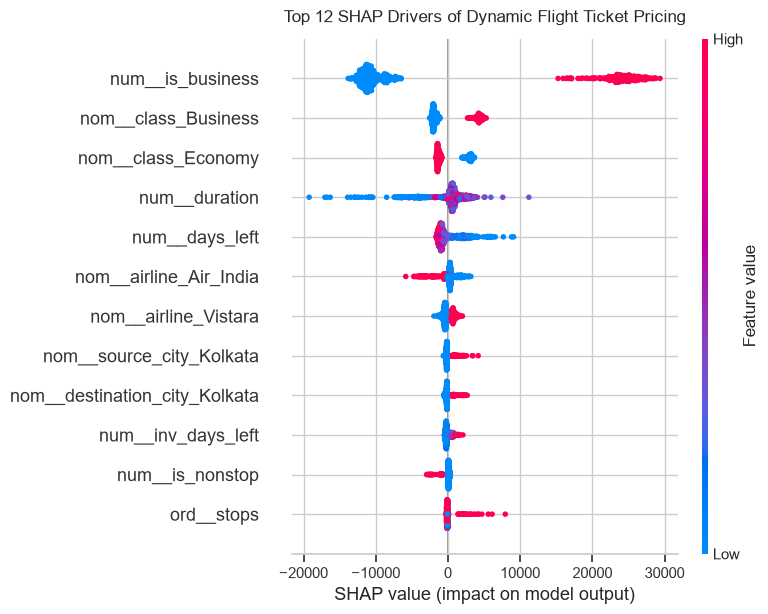

In [7]:
lgbm_pipe = models["LightGBM Regressor (Dynamic Pricing Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Dynamic Flight Ticket Pricing", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_dynamic_pricing.png", dpi=150)
plt.show()

# Segment-Level Error Audit (Economy vs. Business) & Log-Target LightGBM Experiment

In [8]:
lgbm_log = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=600, learning_rate=0.08, num_leaves=63, max_depth=10,
            subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1
        )),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)
lgbm_log.fit(X_train, y_train)

pred_raw_lgbm = np.maximum(models["LightGBM Regressor (Dynamic Pricing Engine)"].predict(X_test), 0.0)
pred_log_lgbm = np.maximum(lgbm_log.predict(X_test), 0.0)

rows = []
for cabin in ["Economy", "Business"]:
    mask = (X_test["class"] == cabin).values
    for label, preds in [("Standard LightGBM", pred_raw_lgbm), ("Log-Target LightGBM", pred_log_lgbm)]:
        rows.append({
            "Cabin_Class": cabin,
            "Model": label,
            "MAE (INR)": mean_absolute_error(y_test[mask], preds[mask]),
            "MAPE (%)": mean_absolute_percentage_error(y_test[mask], preds[mask]) * 100,
        })
display(pd.DataFrame(rows).round(2))

,Cabin_Class,Model,MAE (INR),MAPE (%)
0,Economy,Standard LightGBM,996.19,15.58
1,Economy,Log-Target LightGBM,864.74,12.13
2,Business,Standard LightGBM,3037.86,5.76
3,Business,Log-Target LightGBM,3807.28,7.18
